In [1]:
import os
os.chdir('/Users/yaminiumarani/Desktop/rag_thesis_project')

import sys
sys.path.append('src')

from retriever import (
    baseline_retrieve,
    dynamic_weighted_retrieve,
    get_label_relevance_score,
    get_author_authority,
    make_authority_lookup
)

print("All functions imported successfully! ✅")

All functions imported successfully! ✅


In [2]:
import pandas as pd
import numpy as np
import faiss
from sentence_transformers import SentenceTransformer

# Load everything
df = pd.read_csv('data/github_issues_final.csv', low_memory=False)
model = SentenceTransformer('all-MiniLM-L6-v2')
index = faiss.read_index('data/baseline_faiss.index')
author_df = pd.read_csv('data/author_authority_scores.csv')
authority_lookup = make_authority_lookup(author_df)

# Quick test of imported functions
results = dynamic_weighted_retrieve(
    "window resize not working correctly",
    model, index, df, authority_lookup, top_k=3
)

print("Dataset:", df.shape)
print("Index:", index.ntotal, "vectors")
print("\nTest retrieval — top result:")
print(f"Title: {results[0]['title']}")
print(f"Author: {results[0]['best_author']}")
print(f"Final score: {results[0]['final_score']}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Dataset: (15955, 37)
Index: 15955 vectors

Test retrieval — top result:
Title: Rectangle Doesn't Resize Windows
Author: rxhanson
Final score: 0.5171999931335449


In [3]:
# Build evaluation test set from real issues
# Strategy: sample issues, use their titles as queries
# The issue itself + semantically similar issues = relevant results

import random
random.seed(42)  # reproducibility for your thesis

# Sample 30 diverse test issues - mix of common labels
test_indices = []

# Get issues with different labels for diversity
for label in ['bug', 'enhancement', 'documentation']:
    label_issues = df[df['labels_0_name'] == label].index.tolist()
    sampled = random.sample(label_issues, min(8, len(label_issues)))
    test_indices.extend(sampled)

# Add some random ones for variety
remaining = [i for i in df.index if i not in test_indices]
test_indices.extend(random.sample(remaining, 6))

print(f"Test set size: {len(test_indices)} issues")
print("\nLabel distribution in test set:")
print(df.loc[test_indices, 'labels_0_name'].value_counts())

Test set size: 30 issues

Label distribution in test set:
labels_0_name
bug              14
enhancement       8
documentation     8
Name: count, dtype: int64


In [4]:
# Evaluation: Can each model retrieve the original issue 
# when queried with its title?
# Metrics: Recall@k and MRR (Mean Reciprocal Rank)

def evaluate_retrieval(retrieve_fn, test_indices, top_k=5, **kwargs):
    reciprocal_ranks = []
    hits_at_1 = 0
    hits_at_3 = 0
    hits_at_5 = 0
    
    for test_idx in test_indices:
        query = df['title'].iloc[test_idx]
        results = retrieve_fn(query, top_k=top_k, **kwargs)
        
        # Find rank of the original issue in results
        retrieved_indices = [r['idx'] for r in results]
        
        if test_idx in retrieved_indices:
            rank = retrieved_indices.index(test_idx) + 1
            reciprocal_ranks.append(1.0 / rank)
            if rank == 1:
                hits_at_1 += 1
            if rank <= 3:
                hits_at_3 += 1
            if rank <= 5:
                hits_at_5 += 1
        else:
            reciprocal_ranks.append(0.0)
    
    n = len(test_indices)
    return {
        'MRR': round(np.mean(reciprocal_ranks), 4),
        'Recall@1': round(hits_at_1 / n, 4),
        'Recall@3': round(hits_at_3 / n, 4),
        'Recall@5': round(hits_at_5 / n, 4)
    }

# Evaluate baseline
print("Evaluating BASELINE model...")
baseline_metrics = evaluate_retrieval(
    baseline_retrieve, test_indices, top_k=5,
    model=model, index=index, df=df
)
print(baseline_metrics)

# Evaluate dynamic weighted
print("\nEvaluating DYNAMIC WEIGHTED model...")
dynamic_metrics = evaluate_retrieval(
    dynamic_weighted_retrieve, test_indices, top_k=5,
    model=model, index=index, df=df, authority_lookup=authority_lookup
)
print(dynamic_metrics)

Evaluating BASELINE model...
{'MRR': np.float64(0.8667), 'Recall@1': 0.8667, 'Recall@3': 0.8667, 'Recall@5': 0.8667}

Evaluating DYNAMIC WEIGHTED model...
{'MRR': np.float64(0.655), 'Recall@1': 0.5333, 'Recall@3': 0.7333, 'Recall@5': 0.8333}


In [5]:
def get_partition(label):
    if pd.isna(label):
        return 'other'
    label = str(label).lower()
    if 'bug' in label:
        return 'bug'
    if 'enhancement' in label or 'feature' in label:
        return 'enhancement'
    if 'doc' in label:
        return 'documentation'
    return 'other'

In [6]:
# Complementary metrics: quality of the retrieved SET
# 1. Label match rate - does retrieval match the query's issue type?
# 2. Mean authority - how trustworthy are the retrieved resolutions?

def evaluate_set_quality(retrieve_fn, test_indices, top_k=5, **kwargs):
    label_matches = []
    mean_authorities = []

    for test_idx in test_indices:
        query = df['title'].iloc[test_idx]
        true_label = df['labels_0_name'].iloc[test_idx]
        results = retrieve_fn(query, top_k=top_k, **kwargs)

        # Label match rate (exclude the original issue itself)
        others = [r for r in results if r['idx'] != test_idx]
        if others:
            matches = sum(1 for r in others if get_partition(r.get('label')) == get_partition(true_label))
            label_matches.append(matches / len(others))

        # Mean authority of retrieved set
        authorities = []
        for r in others:
            row = df.iloc[r['idx']]
            best_auth = max(
                get_author_authority(row.get(f'answers_{i}_author'), authority_lookup)
                for i in range(6)
            )
            authorities.append(best_auth)
        if authorities:
            mean_authorities.append(np.mean(authorities))

    return {
        'Label Match Rate': round(np.mean(label_matches), 4),
        'Mean Authority of Retrieved': round(np.mean(mean_authorities), 4)
    }

print("BASELINE set quality:")
baseline_quality = evaluate_set_quality(baseline_retrieve, test_indices, top_k=5,
                                        model=model, index=index, df=df)
print(baseline_quality)

print("\nDYNAMIC set quality:")
dynamic_quality = evaluate_set_quality(dynamic_weighted_retrieve, test_indices, top_k=5,
                                       model=model, index=index, df=df,
                                       authority_lookup=authority_lookup)
print(dynamic_quality)


BASELINE set quality:
{'Label Match Rate': np.float64(0.5833), 'Mean Authority of Retrieved': np.float64(0.1575)}

DYNAMIC set quality:
{'Label Match Rate': np.float64(0.6333), 'Mean Authority of Retrieved': np.float64(0.2782)}


In [7]:
import json

evaluation_results = {
    'test_set_size': len(test_indices),
    'baseline': {
        'retrieval_metrics': {k: float(v) for k, v in baseline_metrics.items()},
        'set_quality': {k: float(v) for k, v in baseline_quality.items()}
    },
    'dynamic_weighted': {
        'retrieval_metrics': {k: float(v) for k, v in dynamic_metrics.items()},
        'set_quality': {k: float(v) for k, v in dynamic_quality.items()}
    },
    'weights_used': {'semantic': 0.5, 'author_authority': 0.3, 'label_relevance': 0.2},
    'generation_model': 'llama3.2:1b'
}

with open('results/evaluation_results.json', 'w') as f:
    json.dump(evaluation_results, f, indent=2)

print("Evaluation results saved!")


Evaluation results saved!


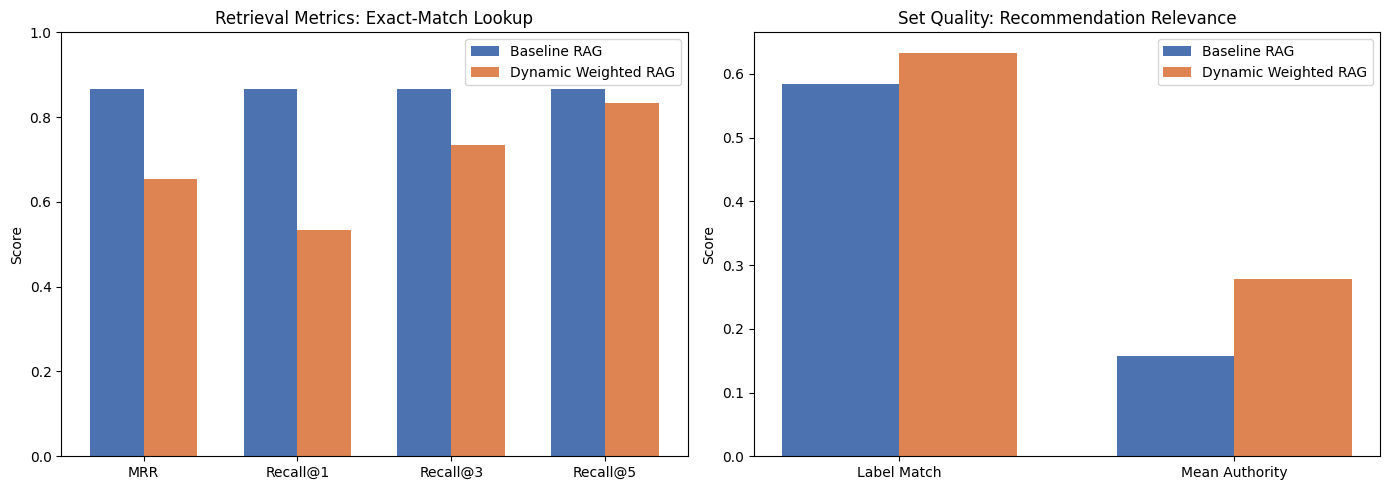

Chart saved to results/evaluation_comparison.png


In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

metrics_names = ['MRR', 'Recall@1', 'Recall@3', 'Recall@5']
baseline_vals = [baseline_metrics[m] for m in metrics_names]
dynamic_vals = [dynamic_metrics[m] for m in metrics_names]

x = np.arange(len(metrics_names))
width = 0.35

axes[0].bar(x - width/2, baseline_vals, width, label='Baseline RAG', color='#4C72B0')
axes[0].bar(x + width/2, dynamic_vals, width, label='Dynamic Weighted RAG', color='#DD8452')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics_names)
axes[0].set_ylabel('Score')
axes[0].set_title('Retrieval Metrics: Exact-Match Lookup')
axes[0].legend()
axes[0].set_ylim(0, 1)

quality_names = ['Label Match Rate', 'Mean Authority of Retrieved']
baseline_q = [baseline_quality[m] for m in quality_names]
dynamic_q = [dynamic_quality[m] for m in quality_names]

x2 = np.arange(len(quality_names))
axes[1].bar(x2 - width/2, baseline_q, width, label='Baseline RAG', color='#4C72B0')
axes[1].bar(x2 + width/2, dynamic_q, width, label='Dynamic Weighted RAG', color='#DD8452')
axes[1].set_xticks(x2)
axes[1].set_xticklabels(['Label Match', 'Mean Authority'])
axes[1].set_ylabel('Score')
axes[1].set_title('Set Quality: Recommendation Relevance')
axes[1].legend()

plt.tight_layout()
plt.savefig('results/evaluation_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print("Chart saved to results/evaluation_comparison.png")
